<a href="https://colab.research.google.com/github/ShaunakSoni28/Synapse/blob/main/Synapse%20Phase%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Synapse: Medical Fine-Tuning or Retrieval?
### Reducing Hallucinations in Neurology Question Answering
CS 6180 Foundations of Generative AI – Final Project · Shaunak Soni, Dev Chauhan, Shivang Raval

This notebook runs the Synapse experiments end to end:

1. Build a neurology question set from MedQA and MedMCQA, labeled as factual recall or multi-step reasoning.
2. Build a retrieval index over open medical text.
3. Run each model in four setups: zero-shot, chain-of-thought (CoT), RAG, and RAG + CoT.
4. Test hallucination detection on MedHallu, with and without the source knowledge.
5. Summarize results, run paired significance tests, and export samples for manual review.

**Before running:** switch to a GPU runtime, accept the model licenses on Hugging Face for MedGemma, Gemma 3, and Llama 3.1, and add your Hugging Face token as a Colab secret named `HF_TOKEN`. For a first pass, set `N_PER_TYPE = 20` to check that everything runs before the full experiment.

## 1. Setup

In [7]:
!pip install -q "transformers>=4.50,<5" accelerate bitsandbytes datasets sentence-transformers faiss-cpu

In [8]:
import os, re, json, glob, gc, random, subprocess
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset
from huggingface_hub import login, hf_hub_download

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN:
    login(token=HF_TOKEN)
else:
    print("No HF_TOKEN found. Add it in Colab's Secrets panel (key icon) with notebook access on, then rerun this cell.")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

assert torch.cuda.is_available(), "Switch to a GPU runtime (Runtime > Change runtime type)."
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(torch.cuda.get_device_name(0), "| compute dtype:", DTYPE)

Tesla T4 | compute dtype: torch.bfloat16


## 2. Configuration
MedGemma 4B is built on Gemma 3 4B, so that pair isolates what medical fine-tuning adds. BioMistral 7B and Llama 3.1 8B add a second medical-versus-general comparison at a larger size. BioMistral was trained from Mistral 7B Instruct v0.1, so adding `mistral-7b` to `ACTIVE_MODELS` gives a second base-model pair.

In [9]:
OUT_DIR = "/content/synapse_outputs"
# To keep results across Colab sessions, save them to Google Drive instead:
# from google.colab import drive; drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive/synapse_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = {
    "medgemma-4b":   dict(hf_id="google/medgemma-4b-it",              kind="vlm",    group="medical", gemma=True),
    "gemma3-4b":     dict(hf_id="google/gemma-3-4b-it",               kind="vlm",    group="general", gemma=True),
    "biomistral-7b": dict(hf_id="BioMistral/BioMistral-7B",           kind="causal", group="medical", gemma=False),
    "llama3.1-8b":   dict(hf_id="meta-llama/Llama-3.1-8B-Instruct",   kind="causal", group="general", gemma=False),
    "mistral-7b":    dict(hf_id="mistralai/Mistral-7B-Instruct-v0.1", kind="causal", group="general", gemma=False),
}
ACTIVE_MODELS = ["medgemma-4b", "gemma3-4b", "biomistral-7b", "llama3.1-8b"]

SETUPS = ["zero_shot", "cot", "rag", "rag_cot"]
N_PER_TYPE = 150                       # evaluation questions per type (factual, reasoning)
TOP_K = 3                              # retrieved passages per question
LOAD_IN_4BIT = True                    # same precision for every model keeps the comparison fair
BATCH_SIZE = {"direct": 8, "cot": 4}
MAX_NEW_TOKENS = {"direct": 32, "cot": 512}

MEDHALLU_CONFIG = "pqa_labeled"        # 1,000 human-annotated items
MEDHALLU_NEURO_ONLY = True
MEDHALLU_N = 200                       # questions sampled; each is tested 4 ways (true/hallucinated x with/without knowledge)

In [10]:
OUT_DIR = "/content/synapse_outputs"
# To keep results across Colab sessions, save them to Google Drive instead:
# from google.colab import drive; drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive/synapse_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = {
    "medgemma-4b":   dict(hf_id="google/medgemma-4b-it",              kind="vlm",    group="medical", gemma=True),
    "gemma3-4b":     dict(hf_id="google/gemma-3-4b-it",               kind="vlm",    group="general", gemma=True),
    "biomistral-7b": dict(hf_id="BioMistral/BioMistral-7B",           kind="causal", group="medical", gemma=False),
    "llama3.1-8b":   dict(hf_id="meta-llama/Llama-3.1-8B-Instruct",   kind="causal", group="general", gemma=False),
    "mistral-7b":    dict(hf_id="mistralai/Mistral-7B-Instruct-v0.1", kind="causal", group="general", gemma=False),
}
ACTIVE_MODELS = ["medgemma-4b", "gemma3-4b", "biomistral-7b", "mistral-7b"]   # add "llama3.1-8b" once Meta approves

SETUPS = ["zero_shot", "cot", "rag", "rag_cot"]
N_PER_TYPE = 150                       # evaluation questions per type (factual, reasoning)
TOP_K = 3                              # retrieved passages per question
LOAD_IN_4BIT = True                    # same precision for every model keeps the comparison fair
BATCH_SIZE = {"direct": 8, "cot": 4}
MAX_NEW_TOKENS = {"direct": 32, "cot": 512}

MEDHALLU_CONFIG = "pqa_labeled"        # 1,000 human-annotated items
MEDHALLU_NEURO_ONLY = True
MEDHALLU_N = 200                       # questions sampled; each is tested 4 ways (true/hallucinated x with/without knowledge)

## 3. Neurology question set
Questions come from the MedQA test split and the MedMCQA validation split. Training splits are skipped because medical models may have been trained on them. A keyword filter keeps neurology questions, and a simple rule labels each one: clinical vignettes count as *reasoning* and short knowledge questions as *factual*. Both steps are heuristic, so spot-check `neuro_questions.csv` before the final analysis. Most reasoning questions come from MedQA and most factual ones from MedMCQA, so also compare question types within each source.

In [11]:
NEURO_TERMS = [
    r"neuro\w*", r"stroke", r"seizure\w*", r"epilep\w*", r"parkinson\w*", r"multiple sclerosis", r"dementia",
    r"alzheimer\w*", r"migraine\w*", r"headache\w*", r"myasthenia", r"guillain", r"meningi\w*", r"encephal\w*",
    r"cerebr\w*", r"cerebell\w*", r"cranial nerve\w*", r"spinal cord", r"aphasia", r"ataxi\w*", r"tremor\w*",
    r"hemipare\w*", r"hemipleg\w*", r"paraplegi\w*", r"amyotrophic", r"huntington\w*", r"subarachnoid",
    r"intracranial", r"glioma\w*", r"glioblastoma", r"demyelinat\w*", r"brain ?stem", r"thalam\w*",
    r"basal ganglia", r"hydrocephal\w*", r"nystagmus", r"bell'?s palsy", r"trigeminal", r"facial nerve",
    r"radiculopath\w*", r"myelopath\w*", r"narcolep\w*", r"transient ischemic", r"spasticity", r"chorea",
]
NEURO_RE = re.compile(r"\b(?:" + "|".join(NEURO_TERMS) + r")\b", re.IGNORECASE)

VIGNETTE_RE = re.compile(
    r"\b\d{1,3}[- ](?:year|month|week|day)s?[- ]old\b|\bpresents? (?:with|to)\b|\bcomes to\b"
    r"|\bbrought to\b|\bis admitted\b|\bexamination shows\b", re.IGNORECASE)

def question_type(question):
    """Clinical vignettes count as multi-step reasoning; short knowledge questions as factual recall."""
    return "reasoning" if VIGNETTE_RE.search(question) or len(question.split()) > 60 else "factual"

In [12]:
rows = []
for i, r in enumerate(load_dataset("GBaker/MedQA-USMLE-4-options", split="test")):
    rows.append(dict(qid=f"medqa-{i}", source="MedQA", question=r["question"].strip(), options=dict(r["options"]),
                     answer=r["answer_idx"], filter_text=r["question"]))
for r in load_dataset("openlifescienceai/medmcqa", split="validation"):
    if r["cop"] not in (0, 1, 2, 3) or r["subject_name"] == "Dental":
        continue
    rows.append(dict(qid=f"medmcqa-{r['id']}", source="MedMCQA", question=r["question"].strip(),
                     options={"A": r["opa"], "B": r["opb"], "C": r["opc"], "D": r["opd"]},
                     answer="ABCD"[r["cop"]], filter_text=f"{r['question']} {r['topic_name'] or ''}"))
pool = pd.DataFrame(rows)

neuro = pool[pool.filter_text.str.contains(NEURO_RE)].drop(columns="filter_text").copy()
neuro["qtype"] = neuro.question.map(question_type)
print("Neurology questions found:\n", neuro.groupby(["qtype", "source"]).size(), sep="")

eval_df = pd.concat([g.sample(min(len(g), N_PER_TYPE), random_state=SEED) for _, g in neuro.groupby("qtype")],
                    ignore_index=True)
eval_df.assign(options=eval_df.options.map(json.dumps)).to_csv(f"{OUT_DIR}/neuro_questions.csv", index=False)
print("\nEvaluation set:\n", eval_df.groupby(["qtype", "source"]).size(), sep="")

README.md:   0%|          | 0.00/654 [00:00<?, ?B/s]

phrases_no_exclude_train.jsonl:   0%|          | 0.00/16.2M [00:00<?, ?B/s]

phrases_no_exclude_test.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/10178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1273 [00:00<?, ? examples/s]

README.md: 0.00B [00:00, ?B/s]

... (3 outputs left out)

Generating train split:   0%|          | 0/182822 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6150 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4183 [00:00<?, ? examples/s]

Neurology questions found:
qtype      source 
factual    MedMCQA     97
           MedQA        1
reasoning  MedMCQA     26
           MedQA      195
dtype: int64

Evaluation set:
qtype      source 
factual    MedMCQA     97
           MedQA        1
reasoning  MedMCQA     14
           MedQA      136
dtype: int64


## 4. Retrieval corpus and index
The default corpus is the neurology textbook (`Neurology_Adams`) from the MedRAG Textbooks collection, which downloads directly from Hugging Face. StatPearls can't be redistributed, so it is optional: set `USE_STATPEARLS = True` to download it from NCBI and chunk it with the MedRAG script (a large download). Passages are retrieved once per question and reused for every model, so all models see the same evidence.

In [13]:
TEXTBOOKS = ["Neurology_Adams"]    # e.g. add "InternalMed_Harrison" or "Pharmacology_Katzung" for wider coverage
USE_STATPEARLS = False

def load_textbook(name):
    path = hf_hub_download("MedRAG/textbooks", f"chunk/{name}.jsonl", repo_type="dataset")
    return pd.read_json(path, lines=True).assign(source=f"textbook:{name}")

parts = [load_textbook(n) for n in TEXTBOOKS]

if USE_STATPEARLS:
    sp_dir = "/content/MedRAG/corpus/statpearls"
    if not os.path.exists("/content/MedRAG"):
        subprocess.run("git clone -q https://github.com/Teddy-XiongGZ/MedRAG.git /content/MedRAG", shell=True, check=True)
    if not glob.glob(f"{sp_dir}/chunk/*.jsonl"):
        for cmd in [f"wget -q https://ftp.ncbi.nlm.nih.gov/pub/litarch/3d/12/statpearls_NBK430685.tar.gz -P {sp_dir}",
                    f"tar -xzf {sp_dir}/statpearls_NBK430685.tar.gz -C {sp_dir}",
                    "cd /content/MedRAG && python src/data/statpearls.py"]:
            subprocess.run(cmd, shell=True, check=True)
    files = glob.glob(f"{sp_dir}/chunk/*.jsonl") or glob.glob(f"{sp_dir}/**/*.jsonl", recursive=True)
    sp = pd.concat([pd.read_json(f, lines=True) for f in files], ignore_index=True)
    parts.append(sp[sp.title.str.contains(NEURO_RE, na=False)].assign(source="statpearls"))

corpus = pd.concat(parts, ignore_index=True)[["id", "title", "content", "source"]]
corpus["passage"] = corpus.title.fillna("").astype(str) + ". " + corpus.content.fillna("").astype(str)
print(corpus.source.value_counts())

chunk/Neurology_Adams.jsonl:   0%|          | 0.00/19.5M [00:00<?, ?B/s]

source
textbook:Neurology_Adams    12370
Name: count, dtype: int64


In [14]:
from sentence_transformers import SentenceTransformer
import faiss

EMBED_MODEL = "NeuML/pubmedbert-base-embeddings"   # biomedical sentence embeddings
embedder = SentenceTransformer(EMBED_MODEL, device="cuda")
emb = embedder.encode(corpus.passage.tolist(), batch_size=128, normalize_embeddings=True,
                      convert_to_numpy=True, show_progress_bar=True).astype("float32")
index = faiss.IndexFlatIP(emb.shape[1])
index.add(emb)

# Retrieve once per question (question + options as the query) so every model sees the same passages
queries = [r.question + " " + " ".join(str(v) for v in r.options.values()) for r in eval_df.itertuples()]
q_emb = embedder.encode(queries, batch_size=64, normalize_embeddings=True, convert_to_numpy=True).astype("float32")
_, hits = index.search(q_emb, TOP_K)

def contains_answer(text, option):
    """Rough check: does the correct option's text appear in the retrieved passages?"""
    opt = str(option).strip().rstrip(".").lower()
    return len(opt) > 3 and re.search(r"\b" + re.escape(opt) + r"\b", text.lower()) is not None

retrieved, retrieval_hit = {}, {}
for r, ids in zip(eval_df.itertuples(), hits):
    retrieved[r.qid] = corpus.passage.iloc[ids].tolist()
    retrieval_hit[r.qid] = contains_answer(" ".join(retrieved[r.qid]), r.options[r.answer])
with open(f"{OUT_DIR}/retrieved_passages.json", "w") as f:
    json.dump(retrieved, f)
print(f"Correct option text found in retrieved passages for {np.mean(list(retrieval_hit.values())):.0%} of questions")

del embedder, emb
gc.collect(); torch.cuda.empty_cache()

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/97 [00:00<?, ?it/s]

Correct option text found in retrieved passages for 12% of questions


## 5. Prompts and model loading
All models get the same prompts and use greedy decoding. Every model is loaded in 4-bit by default, so differences come from the models rather than from numeric precision.

In [15]:
def format_options(options):
    return "\n".join(f"{k}. {v}" for k, v in options.items())

def qa_prompt(row, setup):
    parts = ["Answer the following neurology exam question."]
    if setup in ("rag", "rag_cot"):
        refs = "\n\n".join(f"[{i + 1}] {p}" for i, p in enumerate(retrieved[row["qid"]]))
        parts.append("Reference passages (use them if they are relevant):\n\n" + refs)
    parts.append(f"Question: {row['question']}\n\nOptions:\n{format_options(row['options'])}")
    if setup in ("cot", "rag_cot"):
        parts.append("Think through the question step by step. End with a final line in the form "
                     "'Answer: X', where X is the letter of the correct option.")
    else:
        parts.append("Reply with only the letter of the correct option, in the form 'Answer: X'.")
    return "\n\n".join(parts)

ANSWER_RE = re.compile(r"(?i:answer)\s*(?:(?i:is)\s*)?[:\-]?\s*[\*\(\[]*\s*([A-D])\b")

def parse_choice(text, setup):
    """Return the chosen letter, or None if the output has no parseable answer."""
    found = ANSWER_RE.findall(text)
    if found:
        return found[-1]
    if setup in ("zero_shot", "rag"):
        m = re.match(r"\s*[\*\(\[]*([A-D])\b", text) or re.search(r"(?i:option)\s*\(?([A-D])\b|\(([A-D])\)", text)
        if m:
            return next(g for g in m.groups() if g)
    return None

def medhallu_prompt(case):
    parts = ["Below is a medical question and a proposed answer. Decide whether the answer contains "
             "hallucinated information, meaning anything incorrect, unsupported, or made up."]
    if case["knowledge"]:
        parts.append(f"Background knowledge:\n{case['knowledge_text']}")
    parts.append(f"Question: {case['question']}\n\nProposed answer: {case['answer']}")
    parts.append("Does the proposed answer contain hallucinated information? Reply with only Yes or No.")
    return "\n\n".join(parts)

def parse_yes_no(text):
    m = re.search(r"\b(yes|no)\b", text, re.IGNORECASE)
    return None if m is None else int(m.group(1).lower() == "yes")

In [16]:
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoProcessor, BitsAndBytesConfig
try:
    from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError:
    from transformers import AutoModelForMultimodalLM as AutoVLM

class ChatModel:
    """Loads one model and generates greedy completions for batches of prompts."""

    def __init__(self, name, spec):
        self.name, self.spec = name, spec
        # Gemma 3 is unstable in float16, so on GPUs without bfloat16 its compute runs in float32
        compute = torch.float32 if (spec["gemma"] and DTYPE == torch.float16) else DTYPE
        quant = (BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                    bnb_4bit_compute_dtype=compute) if LOAD_IN_4BIT else None)
        kwargs = dict(device_map="auto", torch_dtype=compute, quantization_config=quant)
        if spec["kind"] == "vlm":   # Gemma 3 4B and MedGemma 4B are image-text models; we only send text
            self.processor = AutoProcessor.from_pretrained(spec["hf_id"])
            self.tok = self.processor.tokenizer
            self.model = AutoVLM.from_pretrained(spec["hf_id"], **kwargs)
        else:
            self.processor = None
            self.tok = AutoTokenizer.from_pretrained(spec["hf_id"])
            self.model = AutoModelForCausalLM.from_pretrained(spec["hf_id"], **kwargs)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        self.model.eval()

    def render(self, prompt):
        if self.processor is not None:
            msgs = [{"role": "user", "content": [{"type": "text", "text": prompt}]}]
            return self.processor.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        if self.tok.chat_template:
            return self.tok.apply_chat_template([{"role": "user", "content": prompt}],
                                                add_generation_prompt=True, tokenize=False)
        return f"{self.tok.bos_token or ''}[INST] {prompt} [/INST]"   # Mistral-style fallback

    @torch.no_grad()
    def generate(self, prompts, max_new_tokens):
        enc = self.tok([self.render(p) for p in prompts], return_tensors="pt", padding=True,
                       add_special_tokens=False).to(self.model.device)
        out = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=self.tok.pad_token_id)
        new_tokens = out[:, enc["input_ids"].shape[1]:]
        return [t.strip() for t in self.tok.batch_decode(new_tokens, skip_special_tokens=True)]

    def unload(self):
        del self.model
        gc.collect()
        torch.cuda.empty_cache()

## 6. MedHallu test cases
MedHallu pairs each question with a true answer and a hallucinated one. Each sampled question is tested four ways: true or hallucinated answer, with or without the source knowledge. The with-knowledge condition plays the role of retrieval.

In [17]:
mh = load_dataset("UTAustin-AIHealth/MedHallu", MEDHALLU_CONFIG, split="train").to_pandas()
mh["knowledge_text"] = mh["Knowledge"].map(lambda k: " ".join(k) if k is not None else "")
if MEDHALLU_NEURO_ONLY:
    neuro_mask = (mh["Question"] + " " + mh["knowledge_text"]).str.contains(NEURO_RE)
    print(f"Neurology-related MedHallu items: {neuro_mask.sum()} of {len(mh)}")
    mh = mh[neuro_mask]
mh = mh.sample(min(len(mh), MEDHALLU_N), random_state=SEED).reset_index(drop=True)

mh_cases = pd.DataFrame([
    dict(case_id=f"mh{i}-{label}-{int(use_k)}", item=i, label=label, knowledge=use_k,
         difficulty=r["Difficulty Level"], question=r["Question"], answer=answer, knowledge_text=r["knowledge_text"])
    for i, r in mh.iterrows()
    for label, answer in [(0, r["Ground Truth"]), (1, r["Hallucinated Answer"])]
    for use_k in (False, True)
])
print(f"{len(mh)} questions -> {len(mh_cases)} test cases")

README.md: 0.00B [00:00, ?B/s]

pqa_labeled/train-00000-of-00001.parquet:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Neurology-related MedHallu items: 111 of 1000
111 questions -> 444 test cases


## 7. Run the experiments
Each model is loaded once, runs the four question-answering setups and the MedHallu cases, and is then unloaded. Results are saved after every batch, so if Colab disconnects, rerun the notebook and this cell continues where it stopped (keep `OUT_DIR` on Google Drive for that).

In [25]:
QA_PATH, MH_PATH = f"{OUT_DIR}/qa_results.csv", f"{OUT_DIR}/medhallu_results.csv"

def done_keys(path, cols):
    if not os.path.exists(path):
        return set()
    return set(map(tuple, pd.read_csv(path, usecols=cols).astype(str).values))

def append_rows(path, rows):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def remaining(name):
    qa_done, mh_done = done_keys(QA_PATH, ["model", "setup", "qid"]), done_keys(MH_PATH, ["model", "case_id"])
    return (sum((name, s, q) not in qa_done for s in SETUPS for q in eval_df.qid)
            + sum((name, c) not in mh_done for c in mh_cases.case_id))

def run_qa(lm):
    done = done_keys(QA_PATH, ["model", "setup", "qid"])
    for setup in SETUPS:
        mode = "cot" if setup in ("cot", "rag_cot") else "direct"
        todo = [r for r in eval_df.to_dict("records") if (lm.name, setup, r["qid"]) not in done]
        for s in tqdm(range(0, len(todo), BATCH_SIZE[mode]), desc=f"{lm.name} | {setup}"):
            batch = todo[s:s + BATCH_SIZE[mode]]
            outputs = lm.generate([qa_prompt(r, setup) for r in batch], MAX_NEW_TOKENS[mode])
            rows = []
            for r, out in zip(batch, outputs):
                pred = parse_choice(out, setup)
                rows.append(dict(model=lm.name, group=lm.spec["group"], setup=setup, qid=r["qid"],
                                 source=r["source"], qtype=r["qtype"], gold=r["answer"], pred=pred,
                                 correct=int(pred == r["answer"]), valid=int(pred is not None),
                                 retrieval_hit=int(retrieval_hit[r["qid"]]) if setup in ("rag", "rag_cot") else None,
                                 output=out))
            append_rows(QA_PATH, rows)

def run_medhallu(lm):
    done = done_keys(MH_PATH, ["model", "case_id"])
    todo = [c for c in mh_cases.to_dict("records") if (lm.name, c["case_id"]) not in done]
    for s in tqdm(range(0, len(todo), BATCH_SIZE["direct"]), desc=f"{lm.name} | MedHallu"):
        batch = todo[s:s + BATCH_SIZE["direct"]]
        outputs = lm.generate([medhallu_prompt(c) for c in batch], 8)
        append_rows(MH_PATH, [dict(model=lm.name, group=lm.spec["group"], case_id=c["case_id"], item=c["item"],
                                   label=c["label"], knowledge=int(c["knowledge"]), difficulty=c["difficulty"],
                                   pred=parse_yes_no(out), output=out) for c, out in zip(batch, outputs)])

for name in ACTIVE_MODELS:
    if remaining(name) == 0:
        print(f"{name}: already done")
        continue
    lm = ChatModel(name, MODELS[name])
    run_qa(lm)
    run_medhallu(lm)
    lm.unload()
    del lm

medgemma-4b: already done
gemma3-4b: already done
biomistral-7b: already done
mistral-7b: already done


## 8. Results

In [26]:
from scipy.stats import binomtest
import matplotlib.pyplot as plt

def mcnemar(a, b):
    """Exact McNemar test on paired 0/1 outcomes for the same questions."""
    only_a = int(((a == 1) & (b == 0)).sum())
    only_b = int(((a == 0) & (b == 1)).sum())
    n = only_a + only_b
    return only_a, only_b, (binomtest(only_a, n, 0.5).pvalue if n else 1.0)

def detection_metrics(d):
    """Hallucination detection scores, with 'hallucinated' as the positive class."""
    y, p = d["label"], d["pred"]
    tp = int(((p == 1) & (y == 1)).sum())
    fp = int(((p == 1) & (y == 0)).sum())
    fn = int(((p != 1) & (y == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return pd.Series(dict(accuracy=(p == y).mean(), precision=precision, recall=recall, f1=f1,
                          accepted_hallucinations=1 - recall, unparseable=p.isna().mean()))

In [20]:
qa = pd.read_csv(QA_PATH)
acc = qa.pivot_table(index="model", columns="setup", values="correct", aggfunc="mean").reindex(columns=SETUPS)
print("Accuracy by model and setup"); display(acc.round(3))

print("Accuracy by question type")
display(qa.pivot_table(index=["model", "qtype"], columns="setup", values="correct", aggfunc="mean")
          .reindex(columns=SETUPS).round(3))

print("Share of outputs with no parseable answer")
display((1 - qa.pivot_table(index="model", columns="setup", values="valid", aggfunc="mean"))
          .reindex(columns=SETUPS).round(3))

print("RAG accuracy when the correct option text was (1) or wasn't (0) in the retrieved passages")
display(qa[qa.setup.isin(["rag", "rag_cot"])]
          .pivot_table(index=["model", "setup"], columns="retrieval_hit", values="correct", aggfunc="mean").round(3))

Accuracy by model and setup


setup,zero_shot,cot,rag,rag_cot
model,,,,
biomistral-7b,0.403,0.294,0.435,0.448
gemma3-4b,0.500,0.383,0.488,0.278
medgemma-4b,0.601,0.613,0.556,0.593
mistral-7b,0.403,0.363,0.415,0.315


Accuracy by question type


setup                    zero_shot    cot    rag  rag_cot
model         qtype                                      
biomistral-7b factual        0.388  0.265  0.418    0.429
              reasoning      0.413  0.313  0.447    0.460
gemma3-4b     factual        0.541  0.510  0.520    0.459
              reasoning      0.473  0.300  0.467    0.160
medgemma-4b   factual        0.663  0.673  0.643    0.643
              reasoning      0.560  0.573  0.500    0.560
mistral-7b    factual        0.429  0.388  0.429    0.306
              reasoning      0.387  0.347  0.407    0.320

Share of outputs with no parseable answer


setup,zero_shot,cot,rag,rag_cot
model,,,,
biomistral-7b,0.004,0.431,0.000,0.036
gemma3-4b,0.000,0.310,0.000,0.460
medgemma-4b,0.004,0.056,0.000,0.044
mistral-7b,0.020,0.153,0.004,0.230


RAG accuracy when the correct option text was (1) or wasn't (0) in the retrieved passages


retrieval_hit            0.0    1.0
model         setup                
biomistral-7b rag      0.390  0.767
              rag_cot  0.399  0.800
gemma3-4b     rag      0.445  0.800
              rag_cot  0.216  0.733
medgemma-4b   rag      0.518  0.833
              rag_cot  0.564  0.800
mistral-7b    rag      0.362  0.800
              rag_cot  0.294  0.467

In [21]:
wide = qa.pivot_table(index="qid", columns=["model", "setup"], values="correct")
tests = []

def compare(label, x, y):
    if x in wide.columns and y in wide.columns:
        pair = wide[[x, y]].dropna()
        only_x, only_y, p = mcnemar(pair[x], pair[y])
        tests.append(dict(comparison=label, n=len(pair), acc_first=pair[x].mean(), acc_second=pair[y].mean(),
                          only_first_right=only_x, only_second_right=only_y, p_value=p))

for m in ACTIVE_MODELS:                       # effect of reasoning and retrieval within each model
    for setup in ["cot", "rag", "rag_cot"]:
        compare(f"{m}: {setup} vs zero_shot", (m, setup), (m, "zero_shot"))
for med, gen in [("medgemma-4b", "gemma3-4b"), ("biomistral-7b", "mistral-7b"), ("biomistral-7b", "llama3.1-8b")]:
    for setup in SETUPS:                      # effect of medical fine-tuning
        compare(f"{med} vs {gen} ({setup})", (med, setup), (gen, setup))
    compare(f"{gen} + RAG vs {med} zero-shot", (gen, "rag"), (med, "zero_shot"))   # main hypothesis
display(pd.DataFrame(tests).round(4))

,comparison,n,acc_first,acc_second,only_first_right,only_second_right,p_value
0,medgemma-4b: cot vs zero_shot,248,0.6129,0.6008,28,25,0.7838
1,medgemma-4b: rag vs zero_shot,248,0.5565,0.6008,26,37,0.2074
2,medgemma-4b: rag_cot vs zero_shot,248,0.5927,0.6008,30,32,0.8991
3,gemma3-4b: cot vs zero_shot,248,0.3831,0.5000,23,52,0.0011
4,gemma3-4b: rag vs zero_shot,248,0.4879,0.5000,33,36,0.8099
5,gemma3-4b: rag_cot vs zero_shot,248,0.2782,0.5000,19,74,0.0000
6,biomistral-7b: cot vs zero_shot,248,0.2944,0.4032,17,44,0.0007
7,biomistral-7b: rag vs zero_shot,248,0.4355,0.4032,27,19,0.3020
8,biomistral-7b: rag_cot vs zero_shot,248,0.4476,0.4032,38,27,0.2145
9,mistral-7b: cot vs zero_shot,248,0.3629,0.4032,33,43,0.3019


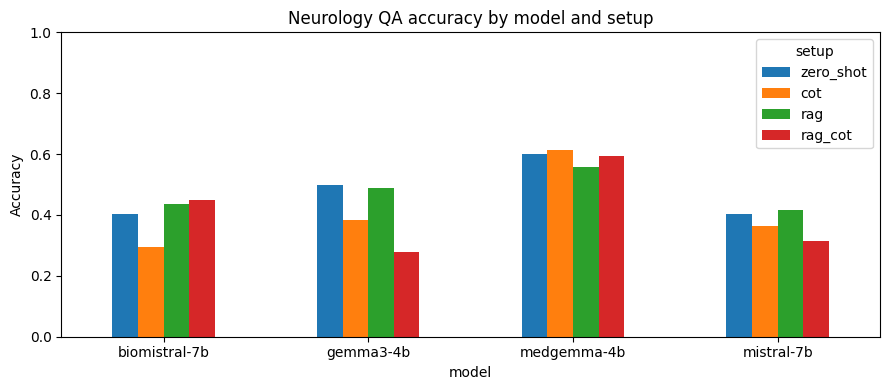

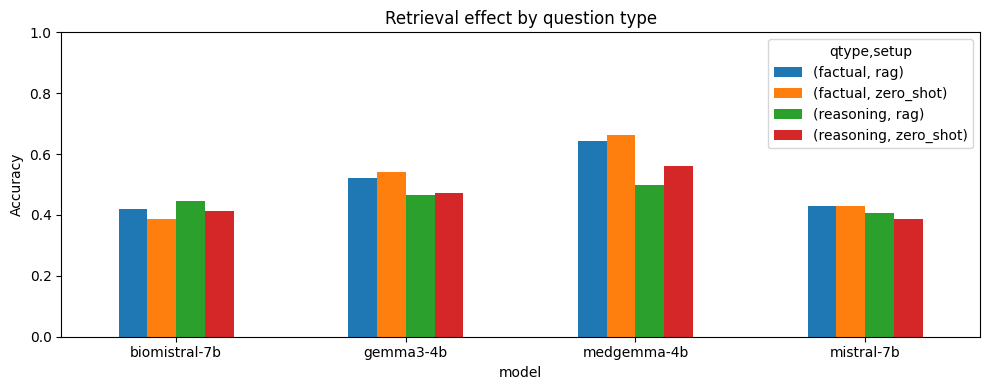

In [22]:
ax = acc.plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1))
ax.set_ylabel("Accuracy"); ax.set_title("Neurology QA accuracy by model and setup")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/accuracy_by_setup.png", dpi=200); plt.show()

by_type = (qa[qa.setup.isin(["zero_shot", "rag"])]
           .pivot_table(index="model", columns=["qtype", "setup"], values="correct", aggfunc="mean"))
ax = by_type.plot.bar(figsize=(10, 4), rot=0, ylim=(0, 1))
ax.set_ylabel("Accuracy"); ax.set_title("Retrieval effect by question type")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rag_by_question_type.png", dpi=200); plt.show()

In [23]:
mhr = pd.read_csv(MH_PATH)
print("Hallucination detection (knowledge = 1 means the source text was provided)")
display(mhr.groupby(["model", "knowledge"])[["label", "pred"]].apply(detection_metrics).round(3))

print("Share of hallucinated answers caught, by difficulty")
display(mhr[mhr.label == 1].pivot_table(index=["model", "knowledge"], columns="difficulty", values="pred",
                                         aggfunc=lambda s: (s == 1).mean()).round(3))

Hallucination detection (knowledge = 1 means the source text was provided)


accuracy  precision  recall     f1  \
model         knowledge                                       
biomistral-7b 0             0.559      0.538   0.838  0.655   
              1             0.523      0.513   0.874  0.647   
gemma3-4b     0             0.482      0.489   0.775  0.599   
              1             0.631      0.710   0.441  0.544   
medgemma-4b   0             0.509      0.750   0.027  0.052   
              1             0.509      1.000   0.018  0.035   
mistral-7b    0             0.491      0.400   0.036  0.066   
              1             0.541      0.846   0.099  0.177   

                         accepted_hallucinations  unparseable  
model         knowledge                                        
biomistral-7b 0                            0.162          0.0  
              1                            0.126          0.0  
gemma3-4b     0                            0.225          0.0  
              1                            0.559          0.0  
medgemma-4b   0                            0.973          0.0  
              1                            0.982          0.0  
mistral-7b    0                            0.964          0.0  
              1                            0.901          0.0

Share of hallucinated answers caught, by difficulty


difficulty                easy   hard  medium
model         knowledge                      
biomistral-7b 0          0.964  0.738   0.854
              1          0.964  0.905   0.780
gemma3-4b     0          0.929  0.643   0.805
              1          0.536  0.333   0.488
medgemma-4b   0          0.036  0.024   0.024
              1          0.036  0.000   0.024
mistral-7b    0          0.036  0.024   0.049
              1          0.143  0.048   0.122

## 9. Files for manual review
`errors_for_review.csv` holds a sample of wrong answers to label by error type. `explanations_for_review.csv` holds RAG + CoT explanations next to their retrieved passages, so you can mark whether each explanation is supported by the passages.

In [24]:
errors = (qa[(qa.correct == 0) & qa.setup.isin(["zero_shot", "rag"])]
          .merge(eval_df[["qid", "question", "options"]], on="qid"))
(errors.sample(min(60, len(errors)), random_state=SEED)
       .assign(error_type="", notes="")
       .to_csv(f"{OUT_DIR}/errors_for_review.csv", index=False))

expl = qa[qa.setup == "rag_cot"].merge(eval_df[["qid", "question"]], on="qid")
expl = expl.sample(min(40, len(expl)), random_state=SEED)
expl["passages"] = expl.qid.map(lambda q: "\n\n".join(retrieved[q]))
expl.assign(supported_by_passages="", notes="").to_csv(f"{OUT_DIR}/explanations_for_review.csv", index=False)
print("Saved review files to", OUT_DIR)

Saved review files to /content/synapse_outputs
